In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn import metrics


from sklearn.metrics import v_measure_score
from sklearn.cluster import DBSCAN


### Load the Dataset

In [19]:
data=pd.read_csv("Mall_Customers.csv")
data.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### Basic Analysis of Dataset

In [20]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [21]:
data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [22]:
data.shape

(200, 5)

### Peprocessing

In [23]:
data.drop(["CustomerID","Age","Gender"],axis=1,inplace=True)

### Data Visualaization

<Axes: xlabel='Annual Income (k$)', ylabel='count'>

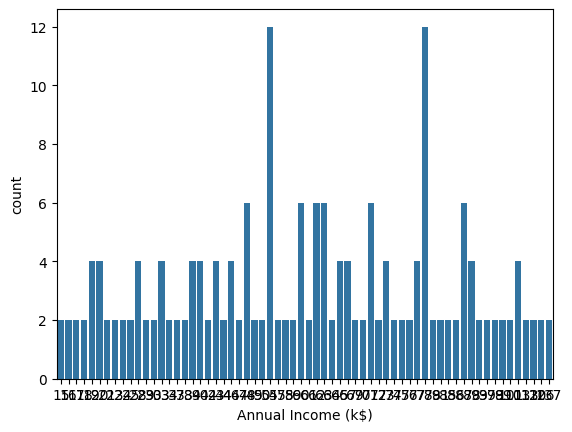

In [24]:
sns.countplot(data=data,x="Annual Income (k$)")

<Axes: xlabel='Spending Score (1-100)', ylabel='count'>

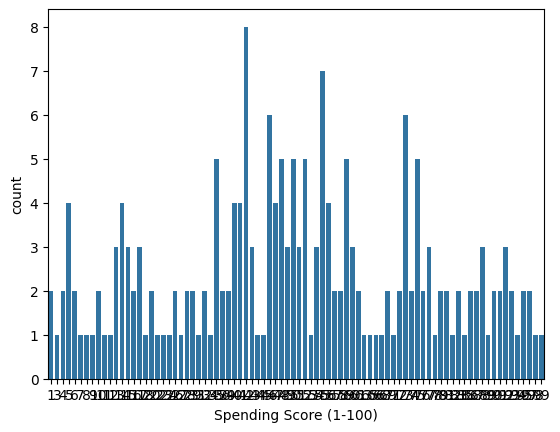

In [25]:
sns.countplot(data=data,x="Spending Score (1-100)")

In [26]:
data.corr()

,Annual Income (k$),Spending Score (1-100)
Annual Income (k$),1.000000,0.009903
Spending Score (1-100),0.009903,1.000000


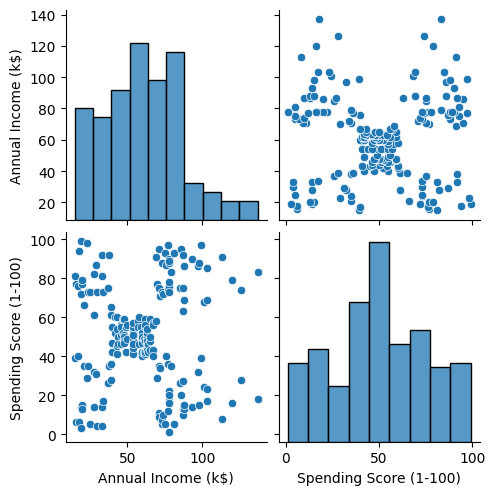

In [27]:
sns.pairplot(data=data)

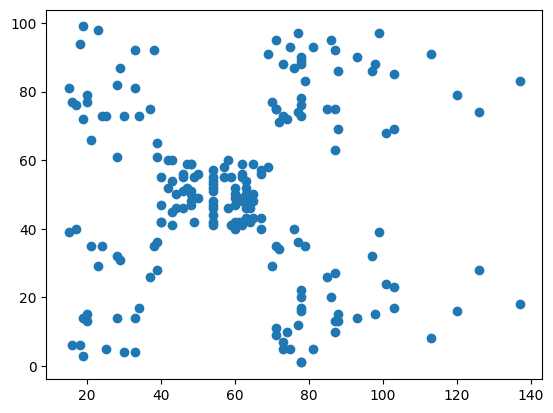

In [28]:
plt.scatter(data["Annual Income (k$)"],data["Spending Score (1-100)"])

### Normalaization the data

In [32]:
Scaler=StandardScaler()
Scaler.fit(data)

,copy,True
,with_mean,True
,with_std,True


In [38]:
Scaler_train=Scaler.transform(data)

### DBSCAN algorithm

In [35]:
dbscan_cluster=DBSCAN(eps=0.5,min_samples=15)

In [39]:
dbscan_cluster.fit(Scaler_train)

,eps,0.5
,min_samples,15
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


In [40]:
print('labels: ',np.unique(dbscan_cluster.labels_))

labels:  [-1  0  1  2  3]


### Visulaising the DBSCAN

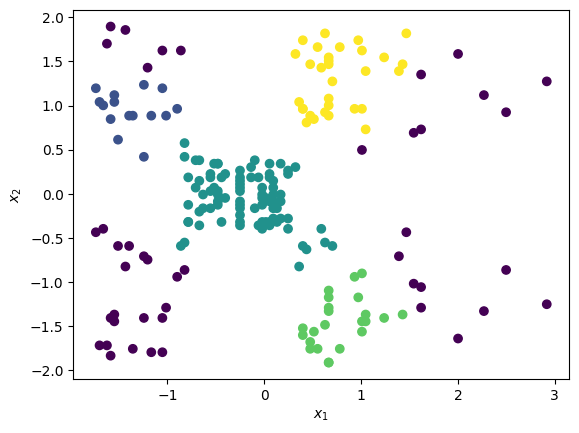

In [46]:
plt.scatter(Scaler_train[:, 0], 
Scaler_train[:, 1], 
c=dbscan_cluster.labels_, 
label=Scaler_train)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.show()

### Number of Clusters

In [48]:
labels=dbscan_cluster.labels_
N_clus=len(set(labels))-(1 if -1 in labels else 0)
print('Estimated no. of clusters: %d' % N_clus)


Estimated no. of clusters: 4


### Identify Noise

In [49]:
n_noise = list(dbscan_cluster.labels_).count(-1)
print('Estimated no. of noise points: %d' % n_noise)

Estimated no. of noise points: 44


In [51]:

from sklearn.metrics import silhouette_score
print('score: ',silhouette_score(Scaler_train,dbscan_cluster.labels_))

score:  0.3687238785666543
